# 2. Làm sạch dữ liệu

Notebook 1 cho thấy 76% số dòng có ít nhất một ô lỗi và khách nào cũng có lỗi, nên không thể xóa dòng, chỉ có thể sửa hoặc khôi phục. Notebook này thực hiện từng quyết định rút ra ở EDA, đo lại từng quyết định bằng số và xuất file sạch.

## Quy trình

| Bước | Việc làm | Dựa trên (notebook 1) |
|---|---|---|
| 1 | Giá trị giả thành NaN | mục 1.4.2 |
| 2 | Bỏ `_` và ép kiểu số | mục 1.4.1 |
| 3 | Giá trị vô lý thành NaN | mục 1.5 |
| 4 | Sửa và điền thiếu. Cách điền được chọn bằng thí nghiệm | mục 1.3, 1.6 |
| 5 | Kiểm tra ràng buộc, báo cáo chất lượng trước và sau | mục 1.9 |
| 6 | Xuất `credit_clean.csv` và báo cáo | |

## Nguyên tắc
- Không dùng nhãn `Credit_Score` ở bước nào, để thông tin của nhãn không lọt vào đặc trưng.
- Code của từng bước nằm trong `src/credit_cleaning.py`. Notebook import các hàm đó và in code ra ngay trước khi chạy, nên code đọc được ở đây chính là code đang chạy. Notebook 3 và 4 cũng dùng lại cùng các hàm này.
- Lỗi nào sửa chính xác được bằng luật thì sửa bằng luật. Chỉ khi không có luật mới ước lượng, và cách ước lượng được chọn bằng thí nghiệm chứ không đoán.

In [1]:
import sys
import json
import warnings
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import credit_cleaning as cc
from notebook_utils import setup_style, show_code, body_run

warnings.filterwarnings('ignore')
setup_style()

raw = pd.read_csv('../data/train.csv', low_memory=False)
print(f'Dữ liệu gốc: {raw.shape[0]:,} dòng, {raw.shape[1]} cột')

LOG = {}

Dữ liệu gốc: 100,000 dòng, 28 cột


## Các hằng số dùng để làm sạch
Mỗi hằng số có nguồn gốc từ notebook 1: danh sách giá trị giả ở mục 1.4.2, miền hợp lệ ở 1.5.1, ngưỡng EMI ở 1.5.2, ngưỡng thu nhập ở 1.5.3. `REPAIR_PLAN` là kế hoạch sửa lỗi cho từng cột, sẽ được kiểm tra bằng thí nghiệm ở bước 4.

In [2]:
show_code(cc, 'NUMERIC_TEXT_COLS', 'PLACEHOLDERS', 'DOMAIN', 'EMI_MAX', 'INCOME_REL_TOL', 'REPAIR_PLAN', 'MODEL_IMPUTE_FEATURES')
assert cc.TARGET not in cc.MODEL_IMPUTE_FEATURES

NUMERIC_TEXT_COLS = ['Age', 'Annual_Income', 'Num_of_Loan', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
                     'Outstanding_Debt', 'Amount_invested_monthly', 'Monthly_Balance']

PLACEHOLDERS = {
    'SSN': '#F%$D@*&8',
    'Occupation': '_______',
    'Credit_Mix': '_',
    'Payment_Behaviour': '!@9#%8',
    'Changed_Credit_Limit': '_',
    'Amount_invested_monthly': '__10000__',
    'Monthly_Balance': '__-333333333333333333333333333__',
}

DOMAIN = {
    'Age': (14, 56),
    'Num_Bank_Accounts': (0, 10),
    'Num_Credit_Card': (1, 10),
    'Interest_Rate': (1, 34),
    'Num_of_Loan': (0, 9),
    'Num_of_Delayed_Payment': (0, 28),
    'Num_Credit_Inquiries': (0, 17),
}

EMI_MAX = 1800        # EMI thật lớn nhất là 1779

INCOME_REL_TOL = 0.5  # thu nhập lệch quá 50% so với trung vị của khách thì bỏ

REPAIR_PLAN = {
    'cust_mode':   ['SSN', 'Occupation', 'Name', 'Credit_Mix'],
    'cust_median': ['Annual_Income', 'Interest_Rate', 'Outstanding_Debt',
                

## Bước 1: giá trị giả thành NaN
Phải làm trước khi bỏ dấu `_`. Nếu làm ngược lại, `__10000__` sẽ thành số 10000 trông như thật (notebook 1, mục 1.4.2). Hàm `add_month_num` thêm số thứ tự tháng từ 1 đến 8. Dữ liệu đã được kiểm tra là sắp đúng thứ tự tháng trong từng khách.

In [3]:
show_code(cc, 'add_month_num', 'mark_placeholders')

def add_month_num(d):
    d = d.copy()
    d['Month_Num'] = d['Month'].map({m: i + 1 for i, m in enumerate(MONTHS)}).astype(int)
    return d

# Bước 1: giá trị giả thành NaN
def mark_placeholders(d, log=None):
    d = d.copy()
    for col, token in PLACEHOLDERS.items():
        is_fake = d[col] == token
        if log is not None:
            log.setdefault('placeholder', {})[col] = int(is_fake.sum())
        d.loc[is_fake, col] = np.nan
    return d


In [4]:
d1 = cc.mark_placeholders(cc.add_month_num(raw), LOG)
pd.DataFrame({'số ô thành NaN': LOG['placeholder'],
              '% dòng': {c: round(n / len(raw) * 100, 2) for c, n in LOG['placeholder'].items()}})

,số ô thành NaN,% dòng
SSN,5572,5.57
Occupation,7062,7.06
Credit_Mix,20195,20.20
Payment_Behaviour,7600,7.60
Changed_Credit_Limit,2091,2.09
Amount_invested_monthly,4305,4.30
Monthly_Balance,9,0.01


In [5]:
shown_cols = ['Credit_Mix', 'Occupation', 'Amount_invested_monthly', 'Payment_Behaviour']
rows = raw.index[(raw.Amount_invested_monthly == '__10000__') & (raw.Credit_Mix == '_')][:3]
pd.concat({'TRƯỚC': raw.loc[rows, shown_cols], 'SAU': d1.loc[rows, shown_cols]}, axis=1)

TRƯỚC                                                                                 SAU                                         \
    Credit_Mix     Occupation Amount_invested_monthly                 Payment_Behaviour Credit_Mix     Occupation Amount_invested_monthly   
161          _       Musician               __10000__   High_spent_Large_value_payments        NaN       Musician                     NaN   
484          _  Media_Manager               __10000__    Low_spent_Small_value_payments        NaN  Media_Manager                     NaN   
716          _       Engineer               __10000__  High_spent_Medium_value_payments        NaN       Engineer                     NaN   

                                       
                    Payment_Behaviour  
161   High_spent_Large_value_payments  
484    Low_spent_Small_value_payments  
716  High_spent_Medium_value_payments

## Bước 2: bỏ `_` và ép kiểu số
Bỏ dấu `_` ở đầu và cuối rồi ép sang `float64` (`'24_'` thành `24.0`). Notebook 1 (mục 1.4.1) đã cho thấy cách này đọc được 100% ô còn lại.

In [6]:
show_code(cc, 'strip_numeric_text')

# Bước 2: bỏ dấu _ rồi ép số. Phải chạy sau bước 1, không thì "__10000__" thành số 10000
def strip_numeric_text(d):
    d = d.copy()
    for col in NUMERIC_TEXT_COLS:
        text = d[col].astype('string').str.replace(r'^_+|_+$', '', regex=True)
        d[col] = pd.to_numeric(text, errors='coerce').astype('float64')
    return d


In [7]:
d2 = cc.strip_numeric_text(d1)

def first_example_with_underscore(s):
    has_underscore = s.astype(str).str.contains('_') & (s != '__10000__')
    return s[has_underscore].iloc[0] if has_underscore.any() else '-'

text_cols = cc.NUMERIC_TEXT_COLS
pd.DataFrame({'dtype trước': raw[text_cols].dtypes.astype(str),
              'dtype sau': d2[text_cols].dtypes.astype(str),
              'ví dụ trước': raw[text_cols].apply(first_example_with_underscore),
              'NaN sau (gồm cả giá trị giả)': d2[text_cols].isna().sum()})

,dtype trước,dtype sau,ví dụ trước,NaN sau (gồm cả giá trị giả)
Age,str,float64,28_,0
Annual_Income,str,float64,34847.84_,0
Num_of_Loan,str,float64,0_,0
Num_of_Delayed_Payment,str,float64,8_,7002
Changed_Credit_Limit,str,float64,_,2091
Outstanding_Debt,str,float64,1328.93_,0
Amount_invested_monthly,str,float64,-,8784
Monthly_Balance,str,float64,__-333333333333333333333333333__,1209


## Bước 3: giá trị vô lý thành NaN
Có ba luật, mỗi luật có bằng chứng riêng ở notebook 1:
- (a) Nằm ngoài miền hợp lệ `DOMAIN` (mục 1.5.1). Gồm cả các giá trị giả nằm trong cột số như `Age = -500` và `Num_of_Loan = -100`.
- (b) EMI lớn hơn 1800 hoặc là số nguyên dương (mục 1.5.2).
- (c) `Annual_Income` lệch hơn 50% so với trung vị của chính khách đó (mục 1.5.3).

In [8]:
show_code(cc, 'mark_invalid')

# Bước 3: giá trị vô lý thành NaN
def mark_invalid(d, log=None):
    d = d.copy()
    log = {} if log is None else log
    invalid_count = log.setdefault('invalid', {})

    for col, (low, high) in DOMAIN.items():
        out_of_range = (d[col] < low) | (d[col] > high)
        invalid_count[col] = int(out_of_range.sum())
        d.loc[out_of_range, col] = np.nan

    emi = d['Total_EMI_per_month']
    bad_emi = (emi > EMI_MAX) | ((emi > 0) & (emi == emi.round(0)))  # EMI thật có số lẻ, số tròn là rác
    invalid_count['Total_EMI_per_month'] = int(bad_emi.sum())
    d.loc[bad_emi, 'Total_EMI_per_month'] = np.nan

    median_income = d.groupby('Customer_ID')['Annual_Income'].transform('median')
    bad_income = (d['Annual_Income'] / median_income - 1).abs() > INCOME_REL_TOL
    invalid_count['Annual_Income'] = int(bad_income.sum())
    d.loc[bad_income, 'Annual_Income'] = np.nan
    return d


In [9]:
d3 = cc.mark_invalid(d2, LOG)
invalid = pd.Series(LOG['invalid'], name='số ô thành NaN').to_frame()
invalid['% dòng'] = (invalid['số ô thành NaN'] / len(raw) * 100).round(2)
invalid

,số ô thành NaN,% dòng
Age,2781,2.78
Num_Bank_Accounts,1345,1.34
Num_Credit_Card,2320,2.32
Interest_Rate,2034,2.03
Num_of_Loan,4348,4.35
Num_of_Delayed_Payment,1380,1.38
Num_Credit_Inquiries,1650,1.65
Total_EMI_per_month,3164,3.16
Annual_Income,999,1.00


### Kiểm tra: ô bị loại có thật là rác không, ô được giữ có thật là đúng không?
Với các cột không đổi theo khách (đã chứng minh ở mục 1.6), có một đáp án độc lập là giá trị phổ biến nhất của chính khách đó. So sánh:
- ô được giữ phải khớp đáp án (gần 100%),
- ô bị loại phải lệch đáp án (gần 100%).

In [10]:
def customer_mode(s):
    return s.dropna().mode().iloc[0] if s.notna().any() else np.nan

rows = []
for col in ['Annual_Income', 'Interest_Rate', 'Num_Bank_Accounts', 'Num_Credit_Card']:
    answer = d3.groupby('Customer_ID')[col].transform(customer_mode)
    kept = d3[col].notna()
    removed = d2[col].notna() & d3[col].isna()
    tol = 1e-6 if col == 'Annual_Income' else 1e-9
    kept_match = np.isclose(d3.loc[kept, col], answer[kept], atol=tol, rtol=1e-9)
    removed_match = np.isclose(d2.loc[removed, col], answer[removed], atol=tol, rtol=1e-9)
    rows.append({'cột': col,
                 'ô được giữ': int(kept.sum()), '% giữ khớp đáp án': round(kept_match.mean() * 100, 2),
                 'ô bị loại': int(removed.sum()), '% loại lệch đáp án': round((~removed_match).mean() * 100, 2)})
pd.DataFrame(rows).set_index('cột')

,ô được giữ,% giữ khớp đáp án,ô bị loại,% loại lệch đáp án
cột,,,,
Annual_Income,99001,100.00,999,100.0
Interest_Rate,97966,100.00,2034,100.0
Num_Bank_Accounts,98655,99.30,1345,100.0
Num_Credit_Card,97680,99.31,2320,100.0


Với `Annual_Income` và `Interest_Rate` (không đổi tuyệt đối), luật loại bỏ tách đúng khoảng 100% giữa giá trị đúng và rác. Với `Num_Bank_Accounts` và `Num_Credit_Card`, một phần nhỏ ô được giữ không khớp mode của khách. Đó là các thay đổi thật (bước nhảy ở mục 1.6), không phải lỗi.

### Kết quả có phụ thuộc vào ngưỡng tần suất (50) không?
Miền hợp lệ được tìm bằng ngưỡng "mỗi giá trị xuất hiện ít nhất 50 lần". Nếu đổi ngưỡng thì kết quả đổi bao nhiêu?

In [11]:
rows = []
for min_count in [10, 20, 50, 100, 300, 1000]:
    row = {'MIN_COUNT': min_count}
    total_removed = 0
    for col in cc.DOMAIN:
        counts = d2[col].dropna().round().astype(int).value_counts().sort_index()
        low, high = body_run(counts, min_count)
        if col not in ('Age', 'Interest_Rate'):
            low = max(low, 0)
        total_removed += int(counts[(counts.index < low) | (counts.index > high)].sum())
        row[col] = f'[{low},{high}]'
    row['tổng ô bị loại'] = total_removed
    rows.append(row)
pd.DataFrame(rows).set_index('MIN_COUNT')

,Age,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Num_of_Delayed_Payment,Num_Credit_Inquiries,tổng ô bị loại
MIN_COUNT,,,,,,,,
10,"[14,56]","[0,10]","[0,11]","[1,34]","[0,9]","[0,28]","[0,17]",15809
20,"[14,56]","[0,10]","[1,11]","[1,34]","[0,9]","[0,28]","[0,17]",15822
50,"[14,56]","[0,10]","[1,10]","[1,34]","[0,9]","[0,28]","[0,17]",15858
100,"[14,56]","[0,10]","[1,10]","[1,34]","[0,9]","[0,28]","[0,17]",15858
300,"[14,56]","[0,10]","[1,10]","[1,34]","[0,9]","[0,26]","[0,16]",16523
1000,"[14,55]","[0,10]","[1,10]","[1,34]","[0,9]","[0,25]","[0,14]",18471


Với ngưỡng từ 10 đến 100, miền hợp lệ gần như không đổi và tổng số ô bị loại chỉ dao động vài chục ô (khoảng 15,8 nghìn, chênh không quá 0,05% số dòng). Chỉ giá trị sát biên như "11 thẻ tín dụng" đổi phía. Từ 300 trở lên bắt đầu loại nhầm giá trị thật hiếm (cận trên của `Num_of_Delayed_Payment` hạ xuống 26, `Num_Credit_Inquiries` xuống 16, thêm hàng trăm ô bị loại), và ở 1000 còn cắt cả tuổi 56. Ngưỡng 50 nằm giữa vùng ổn định, nên kết quả không nhạy với lựa chọn này.

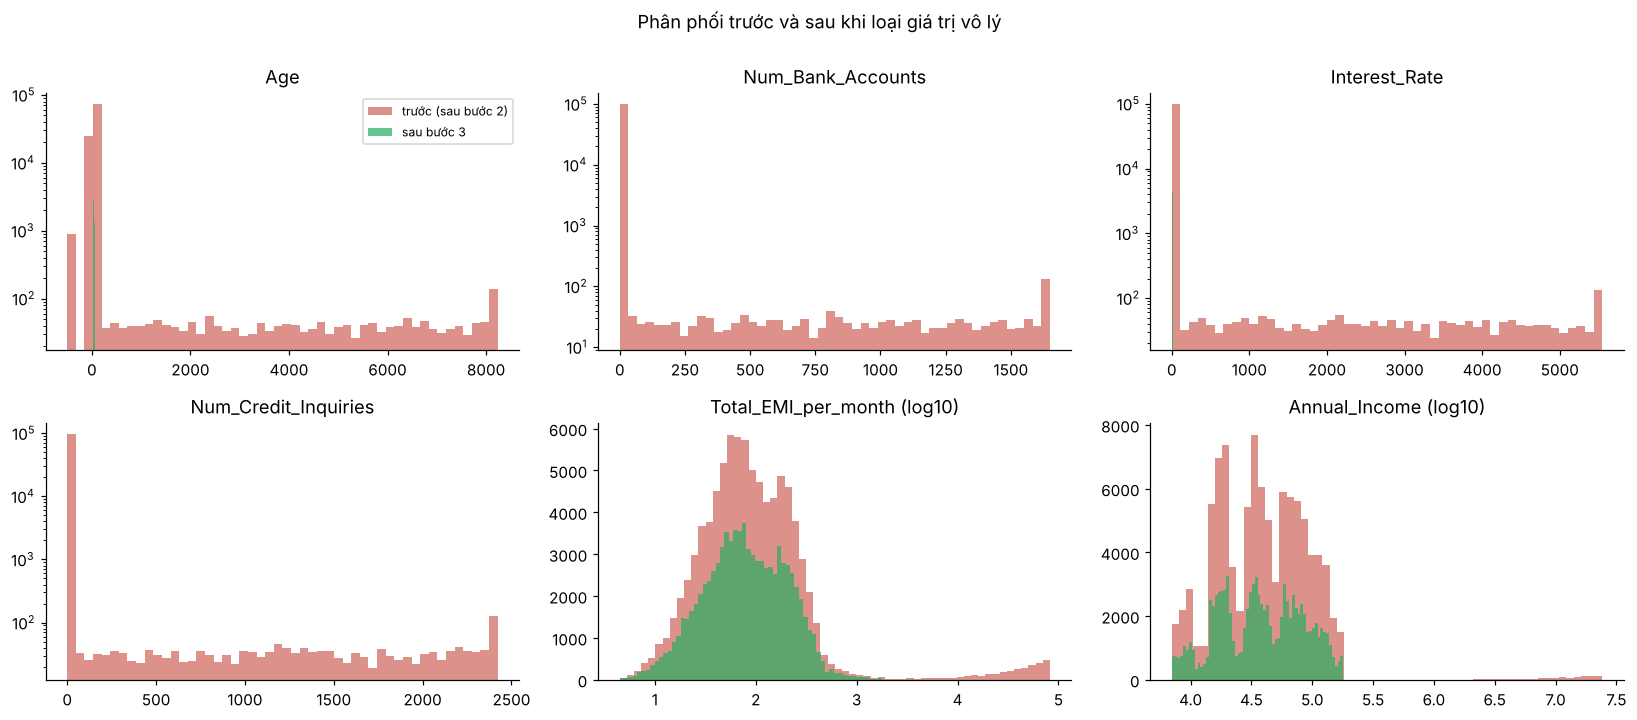

In [12]:
fig, ax = plt.subplots(2, 3, figsize=(15, 6.5))
for a, col in zip(ax.ravel(), ['Age', 'Num_Bank_Accounts', 'Interest_Rate', 'Num_Credit_Inquiries',
                               'Total_EMI_per_month', 'Annual_Income']):
    before, after = d2[col].dropna(), d3[col].dropna()
    if col in ('Total_EMI_per_month', 'Annual_Income'):
        a.hist(np.log10(before[before > 0]), bins=60, alpha=.55, color='#c0392b', label='trước (sau bước 2)')
        a.hist(np.log10(after[after > 0]), bins=60, alpha=.7, color='#27ae60', label='sau bước 3')
        a.set_title(col + ' (log10)')
    else:
        a.hist(before.clip(upper=before.quantile(.999)), bins=50, alpha=.55, color='#c0392b', label='trước (sau bước 2)')
        a.hist(after, bins=50, alpha=.7, color='#27ae60', label='sau bước 3')
        a.set_title(col)
        a.set_yscale('log')
ax[0, 0].legend(fontsize=8)
plt.suptitle('Phân phối trước và sau khi loại giá trị vô lý', y=1.0)
plt.tight_layout()
plt.show()

## Bước 4: sửa và điền thiếu, chọn cách điền bằng thí nghiệm

Sau bước 3, mỗi cột còn các ô NaN (do thiếu từ đầu, do giá trị giả, do giá trị vô lý). Câu hỏi là điền bằng gì. Cách phổ biến là lấy trung bình hoặc trung vị cả cột, nhưng cách đó bỏ qua cấu trúc khách và tháng của dữ liệu. Notebook 1 gợi ý nhiều hướng khác, nên ta thử từng hướng và chọn bằng số liệu.

### 4.1 Các cách điền để so sánh
| Cách | Ý tưởng | Hợp với |
|---|---|---|
| `global_median`, `global_mode` | giá trị phổ biến của cả bảng (đường cơ sở) | |
| `cust_median`, `cust_mode` | giá trị đại diện của chính khách đó | cột không đổi theo khách |
| `nearest` | giá trị ở tháng gần nhất còn hợp lệ của khách | cột có bước nhảy thật |
| `interpolate` | nội suy tuyến tính theo tháng | cột đổi dần |
| `model` | mô hình học máy (HistGradientBoosting) dự đoán giá trị từ các cột khác của cùng dòng | cột phụ thuộc mạnh vào cột khác |
| `model_ratio` | như `model` nhưng dự đoán tỷ lệ so với lương (`cột / Monthly_Inhand_Salary`) rồi nhân lại | cột tiền tỷ lệ với thu nhập |

In [13]:
show_code(cc, 'nearest_fill', 'most_common', 'payment_behaviour_code', 'salary_for_scaling', 'model_fill',
          'fill_numeric', 'fill_categorical')

# Bước 4: điền ô thiếu
def nearest_fill(d, col):
    t = pd.DataFrame({'cust': d['Customer_ID'], 'month': d['Month_Num'], 'value': d[col]})
    t['valid_month'] = t['month'].where(t['value'].notna())
    by_cust = t.groupby('cust')
    prev_value, prev_month = by_cust['value'].ffill(), by_cust['valid_month'].ffill()
    next_value, next_month = by_cust['value'].bfill(), by_cust['valid_month'].bfill()
    gap_prev, gap_next = t['month'] - prev_month, next_month - t['month']
    take_prev = gap_prev.notna() & (gap_next.isna() | (gap_prev <= gap_next))
    filled = pd.Series(np.where(take_prev, prev_value, next_value), index=d.index)
    return filled.where(t['value'].isna(), t['value'])

def most_common(s):
    modes = s.dropna().mode()
    return modes.iloc[0] if len(modes) else np.nan

def payment_behaviour_code(d):
    categories = sorted(d['Payment_Behaviour'].dropna().unique())
    return d['Payment_Behaviour'].map({c: i for i, c in enumerate(categories)}).fillna(-1)

def salary_for

### 4.2 Thí nghiệm che giá trị
Cách đo công bằng một phương pháp điền thiếu: lấy các ô đã biết giá trị hợp lệ, che ngẫu nhiên 10%, điền lại bằng từng cách, rồi so với giá trị thật.
- Cột số: sai số tuyệt đối trung bình chia cho độ lệch chuẩn của cột (NMAE = MAE / σ). Giá trị 0 là hoàn hảo, khoảng 0,8 tương đương đoán bừa bằng trung vị. Chia cho σ để so sánh được giữa các cột khác đơn vị.
- Cột phân loại: độ chính xác (tỷ lệ điền đúng).
- Lặp với 3 hạt ngẫu nhiên khác nhau rồi lấy trung bình.

In [14]:
NUMERIC_TEST = ['Annual_Income', 'Interest_Rate', 'Outstanding_Debt', 'Age', 'Num_Bank_Accounts', 'Num_Credit_Card',
                'Total_EMI_per_month', 'Monthly_Inhand_Salary', 'Num_Credit_Inquiries', 'Num_of_Delayed_Payment',
                'Changed_Credit_Limit', 'Amount_invested_monthly', 'Monthly_Balance']
CATEGORICAL_TEST = ['Occupation', 'SSN', 'Name', 'Credit_Mix', 'Payment_Behaviour']
NUMERIC_STRATEGIES = ['global_median', 'cust_median', 'nearest', 'interpolate', 'model', 'model_ratio']
CATEGORICAL_STRATEGIES = ['global_mode', 'cust_mode', 'nearest']
MONEY_COLS = ['Amount_invested_monthly', 'Monthly_Balance']
SEEDS = (0, 1, 2)


def mask_cells(d, col, seed, fraction=0.10):
    """Che ngẫu nhiên `fraction` số ô đã biết của cột `col`. Trả về bảng đã che và chỉ số các ô bị che."""
    rng = np.random.default_rng(seed)
    known = d.index[d[col].notna()]
    hidden = rng.choice(known, size=int(fraction * len(known)), replace=False)
    masked = d.copy()
    masked.loc[hidden, col] = np.nan
    return masked, hidden


def evaluate_numeric(col):
    """NMAE trung bình qua các hạt ngẫu nhiên, cho từng cách điền."""
    sd = d3[col].std()
    errors = {s: [] for s in NUMERIC_STRATEGIES}
    for seed in SEEDS:
        masked, hidden = mask_cells(d3, col, seed)
        truth = d3.loc[hidden, col]
        for strategy in NUMERIC_STRATEGIES:
            if strategy == 'model_ratio' and col not in MONEY_COLS:
                continue
            filled = cc.fill_numeric(masked, col, strategy).loc[hidden]
            errors[strategy].append((truth - filled).abs().mean() / sd)
    return {s: float(np.mean(v)) if v else np.nan for s, v in errors.items()}


def evaluate_categorical(col):
    """Tỷ lệ điền đúng trung bình qua các hạt ngẫu nhiên, cho từng cách điền."""
    accuracy = {s: [] for s in CATEGORICAL_STRATEGIES}
    for seed in SEEDS:
        masked, hidden = mask_cells(d3, col, seed)
        truth = d3.loc[hidden, col]
        for strategy in CATEGORICAL_STRATEGIES:
            filled = cc.fill_categorical(masked, col, strategy).loc[hidden]
            accuracy[strategy].append(float((filled == truth).mean()))
    return {s: float(np.mean(v)) for s, v in accuracy.items()}


result_num = pd.DataFrame({c: evaluate_numeric(c) for c in NUMERIC_TEST}).T[NUMERIC_STRATEGIES]
result_cat = pd.DataFrame({c: evaluate_categorical(c) for c in CATEGORICAL_TEST}).T[CATEGORICAL_STRATEGIES]
print('Cột số, NMAE (càng thấp càng tốt):')
display(result_num.round(4))
print('Cột phân loại, độ chính xác (càng cao càng tốt):')
display(result_cat.round(3))

Cột số, NMAE (càng thấp càng tốt):


,global_median,cust_median,nearest,interpolate,model,model_ratio
Annual_Income,0.7626,0.0000,0.0000,0.0000,0.0496,NaN
Interest_Rate,0.8290,0.0000,0.0000,0.0000,0.4056,NaN
Outstanding_Debt,0.7358,0.0000,0.0000,0.0000,0.3525,NaN
Age,0.8410,0.0196,0.0083,0.0086,0.6819,NaN
Num_Bank_Accounts,0.8356,0.0035,0.0013,0.0014,0.4673,NaN
Num_Credit_Card,0.8037,0.0042,0.0017,0.0017,0.5459,NaN
Total_EMI_per_month,0.6074,0.0649,0.0261,0.0255,0.2059,NaN
Monthly_Inhand_Salary,0.7623,0.0025,0.0010,0.0011,0.0345,NaN
Num_Credit_Inquiries,0.8368,0.1623,0.0669,0.0694,0.4261,NaN
Num_of_Delayed_Payment,0.8271,0.1208,0.1910,0.1810,0.4615,NaN


Cột phân loại, độ chính xác (càng cao càng tốt):


,global_mode,cust_mode,nearest
Occupation,0.071,1.000,1.000
SSN,0.000,1.000,1.000
Name,0.000,1.000,1.000
Credit_Mix,0.455,1.000,1.000
Payment_Behaviour,0.277,0.258,0.231


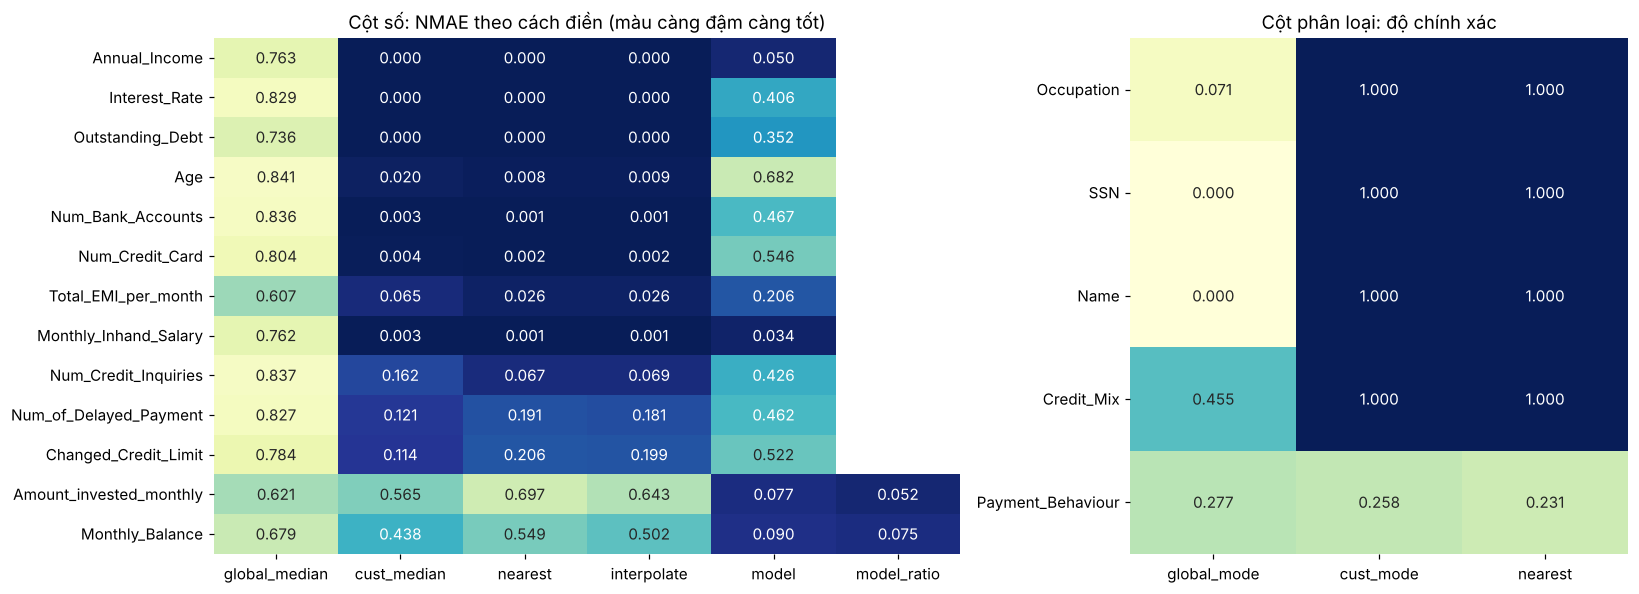

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [3, 2]})
sns.heatmap(result_num, annot=True, fmt='.3f', cmap='YlGnBu_r', ax=ax[0], cbar=False, vmax=0.9)
ax[0].set_title('Cột số: NMAE theo cách điền (màu càng đậm càng tốt)')
sns.heatmap(result_cat, annot=True, fmt='.3f', cmap='YlGnBu', ax=ax[1], cbar=False, vmin=0, vmax=1)
ax[1].set_title('Cột phân loại: độ chính xác')
plt.tight_layout()
plt.show()

### 4.3 Chọn cách điền theo một luật cố định
Với mỗi cột, chọn cách có NMAE thấp nhất. Nếu nhiều cách gần ngang nhau (chênh dưới 0,001) thì chọn cách đơn giản hơn, theo thứ tự `cust_median`, `nearest`, `interpolate`, `model`, `model_ratio`, `global_median`. Kết quả được so với `REPAIR_PLAN` khai báo trong module, và notebook dừng lại nếu hai bên không khớp.

In [16]:
SIMPLEST_FIRST = ['cust_median', 'nearest', 'interpolate', 'model', 'model_ratio', 'global_median']

def pick_strategy(errors, tolerance=0.001):
    best = errors.min()
    return next(s for s in SIMPLEST_FIRST if errors[s] <= best + tolerance)

best_strategy = result_num.apply(pick_strategy, axis=1)
planned = {col: strategy for strategy, cols in cc.REPAIR_PLAN.items() for col in cols}

comparison = pd.DataFrame({
    'cách tốt nhất (thí nghiệm)': best_strategy,
    'NMAE tốt nhất': result_num.min(axis=1).round(4),
    'NMAE khi điền trung vị cả cột': result_num['global_median'].round(4),
    'sai số giảm so với trung vị cả cột': ((1 - result_num.min(axis=1) / result_num['global_median']) * 100).round(1).astype(str) + ' %',
    'REPAIR_PLAN': pd.Series(planned).reindex(best_strategy.index)})
display(comparison)

assert (comparison['cách tốt nhất (thí nghiệm)'] == comparison['REPAIR_PLAN']).all(), 'REPAIR_PLAN không khớp kết quả thí nghiệm'
print('REPAIR_PLAN khớp hoàn toàn với kết quả thí nghiệm')

,cách tốt nhất (thí nghiệm),NMAE tốt nhất,NMAE khi điền trung vị cả cột,sai số giảm so với trung vị cả cột,REPAIR_PLAN
Annual_Income,cust_median,0.0000,0.7626,100.0 %,cust_median
Interest_Rate,cust_median,0.0000,0.8290,100.0 %,cust_median
Outstanding_Debt,cust_median,0.0000,0.7358,100.0 %,cust_median
Age,nearest,0.0083,0.8410,99.0 %,nearest
Num_Bank_Accounts,nearest,0.0013,0.8356,99.8 %,nearest
Num_Credit_Card,nearest,0.0017,0.8037,99.8 %,nearest
Total_EMI_per_month,nearest,0.0255,0.6074,95.8 %,nearest
Monthly_Inhand_Salary,nearest,0.0010,0.7623,99.9 %,nearest
Num_Credit_Inquiries,nearest,0.0669,0.8368,92.0 %,nearest
Num_of_Delayed_Payment,cust_median,0.1208,0.8271,85.4 %,cust_median


REPAIR_PLAN khớp hoàn toàn với kết quả thí nghiệm


Đọc kết quả theo từng nhóm cột:
1. Cột không đổi tuyệt đối (`Annual_Income`, `Interest_Rate`, `Outstanding_Debt`): `cust_median` có sai số 0,000, tức khôi phục chính xác. Điền trung vị cả cột sai tới khoảng 0,74 đến 0,83σ.
2. Cột có bước nhảy thật (`Num_Bank_Accounts`, `Num_Credit_Card`, `Age`, `Total_EMI_per_month`, `Monthly_Inhand_Salary`): `nearest` tốt hơn `cust_median`, sai số giảm khoảng một nửa trở lên. Đúng như dự đoán ở notebook 1, mode của khách kéo giá trị của giai đoạn này sang giai đoạn kia.
3. Cột biến động mạnh: `Num_of_Delayed_Payment` và `Changed_Credit_Limit` hợp với `cust_median`. `Num_Credit_Inquiries` hợp với `nearest` vì giá trị có quán tính theo tháng.
4. `Amount_invested_monthly` và `Monthly_Balance`: các cách dựa vào khách sai khá nhiều (NMAE khoảng 0,44 đến 0,70, trong khi đường cơ sở là 0,62 và 0,68), nhưng mô hình học máy giảm sai số xuống còn khoảng 0,05 đến 0,09. Lý do là hai cột này phụ thuộc chặt vào lương và thói quen chi tiêu của cùng dòng (mục 1.8). Đây là chỗ duy nhất đáng dùng mô hình. Giữa hai dạng mô hình, dự đoán tỷ lệ so với lương (`model_ratio`) tốt hơn dự đoán thẳng giá trị ở cả hai cột (sai số giảm từ 0,077 xuống 0,052 và từ 0,090 xuống 0,075). Lý do hợp lý là tiền đầu tư và số dư tăng theo thu nhập, nên tỷ lệ so với lương ổn định hơn giữa các mức lương. Ở notebook 3 (mục 3.1), cách này cũng sai ít hơn ở riêng nhóm lương cao.
5. Cột phân loại (`SSN`, `Occupation`, `Name`, `Credit_Mix`): điền theo khách đúng khoảng 100%, so với 0 đến 46% nếu điền mode cả cột.
6. `Payment_Behaviour`: không cách nào tốt hơn đoán (độ chính xác khoảng 0,23 đến 0,28, ngang với đoán theo tần suất). Thói quen này đổi ngẫu nhiên theo tháng nên các tháng khác không cho biết gì. Điền bừa chỉ thêm nhiễu, nên ta giữ thành một nhóm riêng `Unknown` (7,6% số dòng) và để mô hình tự quyết định có dùng thông tin này hay không.

### 4.4 Hai trường hợp sửa bằng luật, không cần ước lượng

In [17]:
show_code(cc, 'parse_history_months', 'split_loan_types', 'count_loan_types', 'rebuild_loan_count', 'rebuild_credit_history')

# '22 Years and 9 Months' -> 273
def parse_history_months(x):
    m = re.match(r'(\d+) Years and (\d+) Months', str(x))
    return int(m.group(1)) * 12 + int(m.group(2)) if m else np.nan

def split_loan_types(x):
    parts = re.split(r',\s*', str(x).replace(' and ', ' '))
    return [p.strip() for p in parts if p.strip()]

def count_loan_types(x):
    if pd.isna(x) or x == 'No Loan':
        return 0
    return len(split_loan_types(x))

def rebuild_loan_count(d, log):
    log['Num_of_Loan'] = int(d['Num_of_Loan'].isna().sum())
    d['Num_of_Loan'] = d['Type_of_Loan'].map(count_loan_types)

def rebuild_credit_history(d, log):
    months = d['Credit_History_Age'].map(parse_history_months)
    offset = (months - d['Month_Num']).groupby(d['Customer_ID']).transform('median')
    log['Credit_History_Age'] = int(months.isna().sum())
    d['Credit_History_Months'] = months.fillna(offset + d['Month_Num']).fillna(months.median())
    d.drop(columns='Credit_History_Age', inplace=True)


In [18]:
has_count = d3.Num_of_Loan.notna()
types_listed = d3.Type_of_Loan.map(cc.count_loan_types)
match = (types_listed[has_count] == d3.Num_of_Loan[has_count]).mean()
print(f'(a) Num_of_Loan hợp lệ khớp số loại vay: {match:.2%} trên {has_count.sum():,} dòng, nên tính lại được chính xác')

months = d3.Credit_History_Age.map(cc.parse_history_months)
rng = np.random.default_rng(0)
known = months.index[months.notna()]
hidden = rng.choice(known, size=int(.1 * len(known)), replace=False)
masked = months.copy()
masked.loc[hidden] = np.nan
offset = (masked - d3.Month_Num).groupby(d3.Customer_ID).transform('median')
predicted = offset + d3.Month_Num
exact = (predicted.loc[hidden] == months.loc[hidden]).mean()
worst = int((predicted.loc[hidden] - months.loc[hidden]).abs().max())
print(f'(b) Credit_History_Age: tính lại đúng {exact:.2%} số ô bị che (sai lệch lớn nhất {worst} tháng)')

(a) Num_of_Loan hợp lệ khớp số loại vay: 100.00% trên 95,652 dòng, nên tính lại được chính xác
(b) Credit_History_Age: tính lại đúng 100.00% số ô bị che (sai lệch lớn nhất 0 tháng)


### 4.5 Áp dụng kế hoạch sửa lỗi
Hàm `repair` thực hiện cả kế hoạch đã kiểm tra, theo thứ tự: nhóm `Unknown` cho `Payment_Behaviour`, `No Loan` cho `Type_of_Loan`, cột phân loại theo khách, cột số theo `cust_median` rồi `nearest`, `Num_of_Loan` tính từ `Type_of_Loan`, `Credit_History_Age` đổi sang số tháng, và cuối cùng là mô hình `model_ratio` cho hai cột tiền. Mô hình chạy sau cùng để dùng các cột đã sạch (kể cả lương) làm đầu vào và làm mẫu số.

In [19]:
show_code(cc, 'fill_columns', 'repair', 'finalize')

def fill_columns(d, cols, strategy, log):
    for col in cols:
        log[col] = int(d[col].isna().sum())
        if strategy == 'cust_mode':
            d[col] = fill_categorical(d, col, strategy)
        else:
            d[col] = fill_numeric(d, col, strategy)

def repair(d, plan=REPAIR_PLAN, log=None):
    d = d.copy()
    log = {} if log is None else log
    repaired = log.setdefault('repaired', {})

    # không cách nào đoán tốt hơn ngẫu nhiên nên giữ thành nhóm Unknown
    repaired['Payment_Behaviour'] = int(d['Payment_Behaviour'].isna().sum())
    d['Payment_Behaviour'] = d['Payment_Behaviour'].fillna('Unknown')

    # trống nghĩa là khách không vay
    repaired['Type_of_Loan'] = int(d['Type_of_Loan'].isna().sum())
    d['Type_of_Loan'] = d['Type_of_Loan'].fillna('No Loan')

    fill_columns(d, plan['cust_mode'], 'cust_mode', repaired)
    fill_columns(d, plan['cust_median'], 'cust_median', repaired)
    fill_columns(d, plan['nearest'], 'nearest', repaired)

    rebuild_loan_c

In [20]:
d4 = cc.repair(d3, log=LOG)
clean_df = cc.finalize(d4)

special_methods = {'Payment_Behaviour': "nhóm 'Unknown'", 'Num_of_Loan': 'tính từ Type_of_Loan',
                   'Credit_History_Age': 'phép cộng (độ lệch theo tháng)', 'Type_of_Loan': "'No Loan' (không có khoản vay)"}
repaired = pd.DataFrame({'ô được sửa': LOG['repaired']})
repaired['cách sửa'] = [planned.get(c, special_methods.get(c, '')) for c in repaired.index]
repaired['% dòng'] = (repaired['ô được sửa'] / len(raw) * 100).round(2)
repaired.sort_values('ô được sửa', ascending=False)

,ô được sửa,cách sửa,% dòng
Credit_Mix,20195,cust_mode,20.20
Monthly_Inhand_Salary,15002,nearest,15.00
Type_of_Loan,11408,'No Loan' (không có khoản vay),11.41
Name,9985,cust_mode,9.98
Credit_History_Age,9030,phép cộng (độ lệch theo tháng),9.03
Amount_invested_monthly,8784,model_ratio,8.78
Num_of_Delayed_Payment,8382,cust_median,8.38
Payment_Behaviour,7600,nhóm 'Unknown',7.60
Occupation,7062,cust_mode,7.06
SSN,5572,cust_mode,5.57


## Bước 5: kiểm tra sau khi làm sạch
### 5.1 Các ràng buộc phải thỏa
Hàm `validate_clean` kiểm tra 12 ràng buộc rút ra từ EDA: không còn ô thiếu hay giá trị giả, mọi cột nằm trong miền hợp lệ, các cột không đổi theo khách đúng là không đổi, `Num_of_Loan` khớp `Type_of_Loan`, lịch sử tín dụng tăng đúng 1 tháng mỗi tháng.

In [21]:
show_code(cc, 'validate_clean')

def validate_clean(d):
    by_cust = d.groupby('Customer_ID')
    return {
        'Không còn ô thiếu': int(d.isna().sum().sum()) == 0,
        'Không còn placeholder': all((d[c].astype(str) != t).all() for c, t in PLACEHOLDERS.items() if c in d),
        'Mọi cột đếm nằm trong miền hợp lệ': all(d[c].between(lo, hi).all() for c, (lo, hi) in DOMAIN.items()),
        'EMI trong [0, 1800]': bool(d['Total_EMI_per_month'].between(0, EMI_MAX).all()),
        'Mỗi khách đúng 1 SSN / nghề / tên / Credit_Mix': all(by_cust[c].nunique().eq(1).all()
                                                           for c in ['SSN', 'Occupation', 'Name', 'Credit_Mix']),
        'Mỗi khách 1 mức Annual_Income / Interest_Rate / Outstanding_Debt': all(
            by_cust[c].nunique().eq(1).all() for c in ['Annual_Income', 'Interest_Rate', 'Outstanding_Debt']),
        'Num_of_Loan = số loại vay': bool((d['Type_of_Loan'].map(count_loan_types) == d['Num_of_Loan']).all()),
        'Khách "No Loan" ⇔ Num_of_Loan

In [22]:
checks = cc.validate_clean(clean_df)
pd.Series(checks, name='đạt').to_frame()

,đạt
Không còn ô thiếu,True
Không còn placeholder,True
Mọi cột đếm nằm trong miền hợp lệ,True
"EMI trong [0, 1800]",True
Mỗi khách đúng 1 SSN / nghề / tên / Credit_Mix,True
Mỗi khách 1 mức Annual_Income / Interest_Rate / Outstanding_Debt,True
Num_of_Loan = số loại vay,True
"Khách ""No Loan"" ⇔ Num_of_Loan = 0",True
Tuổi trong 1 khách chênh tối đa 1,True
Credit_History tăng đúng +1/tháng,True


In [23]:
assert all(checks.values()), 'Có ràng buộc không đạt'
print('Cả', len(checks), 'ràng buộc đều đạt')

Cả 12 ràng buộc đều đạt


### 5.2 Báo cáo chất lượng dữ liệu, trước và sau

In [24]:
before = pd.read_csv('../data/reports/quality_before.csv', index_col=0)
renamed = {'Credit_History_Age': 'Credit_History_Months'}
after_dtype = clean_df.dtypes.astype(str)

report = before[['dtype_goc', 'thieu', 'placeholder', 'vo_ly']].copy()
report.columns = ['dtype_trước', 'thiếu_trước', 'placeholder_trước', 'vô_lý_trước']
report['tổng_ô_lỗi_trước'] = report[['thiếu_trước', 'placeholder_trước', 'vô_lý_trước']].sum(axis=1)
report['ô_được_sửa'] = pd.Series(LOG['repaired']).reindex(report.index).fillna(0).astype(int)
report['dtype_sau'] = [after_dtype.get(renamed.get(c, c), '') for c in report.index]
report['thiếu_sau'] = [int(clean_df[renamed.get(c, c)].isna().sum()) for c in report.index]
report['placeholder_sau'] = [int((clean_df[c].astype(str) == cc.PLACEHOLDERS[c]).sum()) if c in cc.PLACEHOLDERS else 0
                             for c in report.index]
changed = (report['tổng_ô_lỗi_trước'] > 0) | (report['dtype_trước'] != report['dtype_sau']) | (report['ô_được_sửa'] > 0)
report = report[changed]
report.to_csv('../data/reports/data_quality_report.csv')
display(report)

total_before = int(before[['thieu', 'placeholder', 'vo_ly']].sum().sum())
total_after = int(clean_df.isna().sum().sum()) + int(report.placeholder_sau.sum())
print(f'Tổng ô thiếu, giả hoặc vô lý trước: {total_before:,} ({total_before / raw.size:.2%} số ô), sau: {total_after}')

,dtype_trước,thiếu_trước,placeholder_trước,vô_lý_trước,tổng_ô_lỗi_trước,ô_được_sửa,dtype_sau,thiếu_sau,placeholder_sau
Name,str,9985,0,0,9985,9985,str,0,0
Age,str,0,0,2781,2781,2781,int64,0,0
SSN,str,0,5572,0,5572,5572,str,0,0
Occupation,str,0,7062,0,7062,7062,str,0,0
Annual_Income,str,0,0,999,999,999,float64,0,0
Monthly_Inhand_Salary,float64,15002,0,0,15002,15002,float64,0,0
Num_Bank_Accounts,int64,0,0,1345,1345,1345,int64,0,0
Num_Credit_Card,int64,0,0,2320,2320,2320,int64,0,0
Interest_Rate,int64,0,0,2034,2034,2034,int64,0,0
Num_of_Loan,str,0,0,4348,4348,4348,int64,0,0


Tổng ô thiếu, giả hoặc vô lý trước: 126,926 (4.53% số ô), sau: 0


In [25]:
bad_rows = d3.drop(columns=['Type_of_Loan']).isna().any(axis=1)
complete_customers = int((~bad_rows).groupby(d3.Customer_ID).all().sum())
print(f'Dòng còn ít nhất 1 ô NaN sau bước 1 đến 3 (thiếu, giả hoặc vô lý): {bad_rows.sum():,} ({bad_rows.mean():.1%})')
print(f'Nếu xóa các dòng này chỉ còn {(~bad_rows).sum():,} dòng ({(~bad_rows).mean():.1%}), '
      f'số khách còn đủ cả 8 tháng: {complete_customers:,} / 12,500')

Dòng còn ít nhất 1 ô NaN sau bước 1 đến 3 (thiếu, giả hoặc vô lý): 70,517 (70.5%)
Nếu xóa các dòng này chỉ còn 29,483 dòng (29.5%), số khách còn đủ cả 8 tháng: 0 / 12,500


Xóa dòng lỗi sẽ mất hơn 70% dữ liệu và phá cấu trúc 8 tháng của mỗi khách (không còn khách nào đủ 8 tháng). Vậy sửa và khôi phục là lựa chọn duy nhất khả thi.

Về con số: ở notebook 1 (mục 1.9) là 76,3% số dòng và 4,8% số ô có vấn đề. Số đó tính cả ô chỉ sai định dạng (số dính dấu `_` như `'24_'`, loại lỗi này sửa được ở bước 2 mà không mất thông tin) và không tính `Type_of_Loan` trống (vì nghĩa là không vay). Ở đây ta đếm ô thiếu, giả và vô lý: 126.926 ô, trong đó 11.408 là `Type_of_Loan` trống được điền `No Loan`, và 70,5% số dòng còn ít nhất một ô trống thật sau bước 1 đến 3. Hai cách đếm có định nghĩa khác nhau nên con số khác nhau, không mâu thuẫn.

### 5.3 Trực quan hóa trước và sau

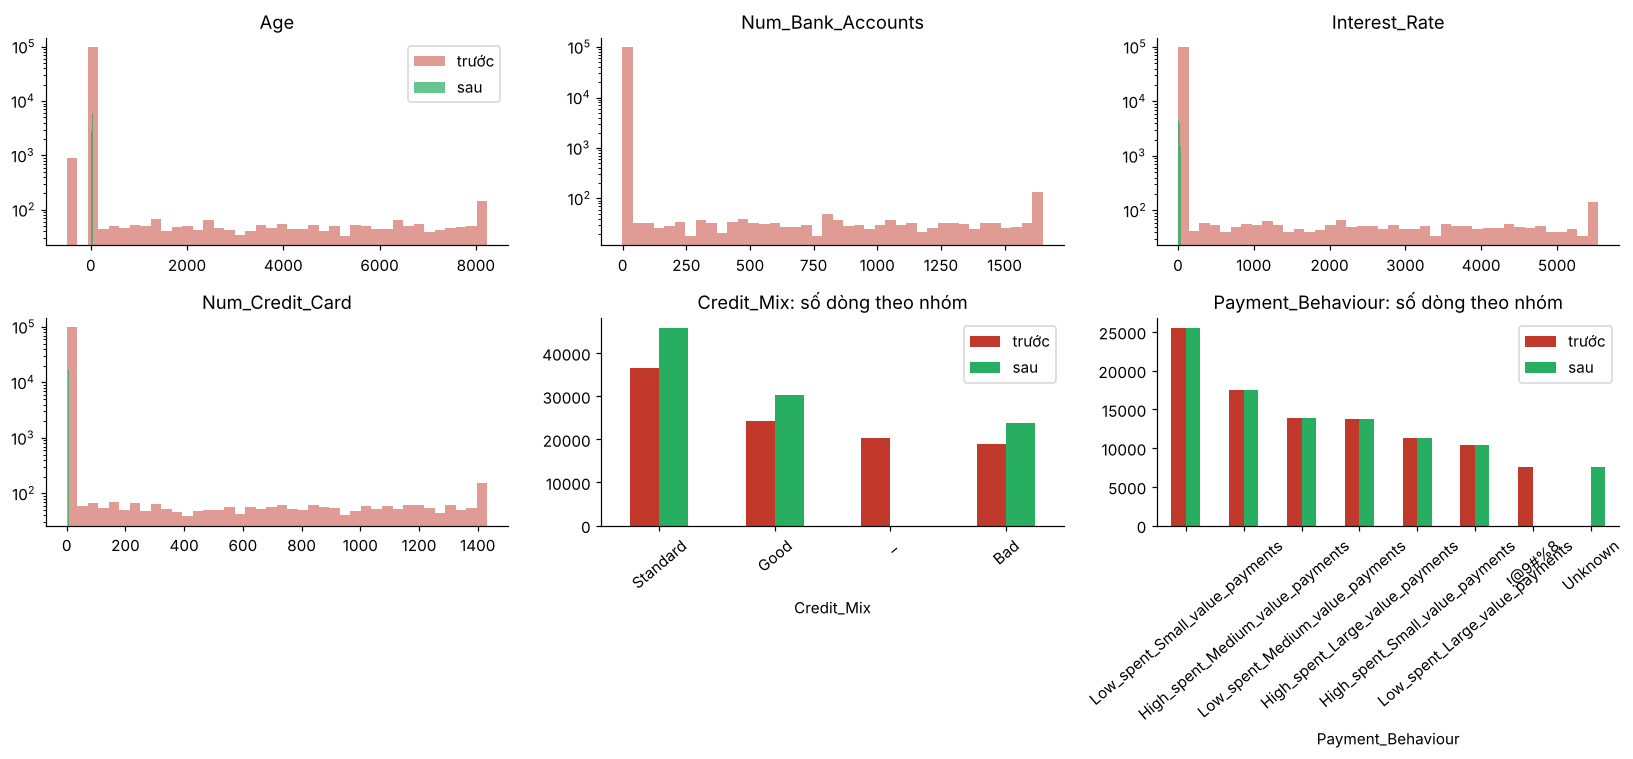

In [26]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, col in zip(ax.ravel()[:4], ['Age', 'Num_Bank_Accounts', 'Interest_Rate', 'Num_Credit_Card']):
    before_values = d2[col].dropna()
    a.hist(before_values.clip(upper=before_values.quantile(.999)), bins=40, color='#c0392b', alpha=.5, label='trước')
    a.hist(clean_df[col], bins=40, color='#27ae60', alpha=.7, label='sau')
    a.set_yscale('log')
    a.set_title(col)
ax[0, 0].legend()
for a, col in zip(ax.ravel()[4:], ['Credit_Mix', 'Payment_Behaviour']):
    counts = pd.concat({'trước': raw[col].value_counts(), 'sau': clean_df[col].value_counts()}, axis=1).fillna(0)
    counts.plot(kind='bar', ax=a, color=['#c0392b', '#27ae60'], rot=40)
    a.set_title(col + ': số dòng theo nhóm')
plt.tight_layout()
plt.show()

In [27]:
base = cc.strip_numeric_text(cc.add_month_num(raw))
base['Credit_History_Months'] = raw.Credit_History_Age.map(cc.parse_history_months)

rows = []
for col in clean_df.columns:
    if col in base.columns and col not in ('Month_Num', 'Credit_Score'):
        if clean_df[col].dtype == object or str(clean_df[col].dtype) == 'str':
            same = clean_df[col].astype(str).values == base[col].astype(str).values
        else:
            same = np.isclose(clean_df[col].astype(float), base[col].astype(float), equal_nan=True)
        rows.append({'cột': col, '% ô bị thay đổi': round((1 - np.mean(same)) * 100, 2)})

changed_share = pd.DataFrame(rows).set_index('cột').sort_values('% ô bị thay đổi', ascending=False)
changed_share[changed_share['% ô bị thay đổi'] > 0].T

cột,Credit_Mix,Monthly_Inhand_Salary,Type_of_Loan,Name,Credit_History_Months,Amount_invested_monthly,Num_of_Delayed_Payment,Payment_Behaviour,Occupation,SSN,Num_of_Loan,Num_Credit_Inquiries,Total_EMI_per_month,Age,Num_Credit_Card,Changed_Credit_Limit,Interest_Rate,Num_Bank_Accounts,Monthly_Balance,Annual_Income
% ô bị thay đổi,20.19,15.0,11.41,9.98,9.03,8.78,8.38,7.6,7.06,5.57,4.35,3.62,3.16,2.78,2.32,2.09,2.03,1.34,1.21,1.0


## Bước 6: kiểm tra lại với hàm `clean()` và xuất file
Notebook 3 và 4 gọi thẳng `clean()` trong `src/credit_cleaning.py`. Ta kiểm tra `clean()` cho ra đúng kết quả vừa chạy từng bước ở trên:

In [28]:
reference, reference_log = cc.clean(raw, return_log=True)
pd.testing.assert_frame_equal(clean_df.reset_index(drop=True), reference.reset_index(drop=True))
assert reference_log['repaired'] == LOG['repaired']
assert reference_log['invalid'] == LOG['invalid']
assert reference_log['placeholder'] == LOG['placeholder']
print('Chạy từng bước trong notebook và gọi clean() cho cùng một kết quả, từng ô')

Chạy từng bước trong notebook và gọi clean() cho cùng một kết quả, từng ô


In [29]:
clean_df.to_csv('../data/credit_clean.csv', index=False)
with open('../data/reports/cleaning_log.json', 'w') as f:
    json.dump({k: {c: int(n) for c, n in v.items()} for k, v in LOG.items()}, f, ensure_ascii=False, indent=1)
print('Đã lưu data/credit_clean.csv', clean_df.shape, '| data/reports/data_quality_report.csv | data/reports/cleaning_log.json')
clean_df.head(3).T

Đã lưu data/credit_clean.csv (100000, 29) | data/reports/data_quality_report.csv | data/reports/cleaning_log.json


,0,1,2
ID,0x1602,0x1603,0x1604
Customer_ID,CUS_0xd40,CUS_0xd40,CUS_0xd40
Month,January,February,March
Month_Num,1,2,3
Name,Aaron Maashoh,Aaron Maashoh,Aaron Maashoh
Age,23,23,23
SSN,821-00-0265,821-00-0265,821-00-0265
Occupation,Scientist,Scientist,Scientist
Annual_Income,19114.12,19114.12,19114.12
Monthly_Inhand_Salary,1824.843333,1824.843333,1824.843333


In [30]:
pd.DataFrame({'dtype': clean_df.dtypes.astype(str), 'số giá trị khác nhau': clean_df.nunique(),
              'min': clean_df.min(numeric_only=True), 'max': clean_df.max(numeric_only=True)})

,dtype,số giá trị khác nhau,min,max
Age,int64,43,14.000000,56.000000
Amount_invested_monthly,float64,99824,0.000000,1977.326102
Annual_Income,float64,12488,7005.930000,179987.280000
Changed_Credit_Limit,float64,4375,-6.490000,36.970000
Credit_History_Months,int64,404,1.000000,404.000000
Credit_Mix,str,3,NaN,NaN
Credit_Score,str,3,NaN,NaN
Credit_Utilization_Ratio,float64,100000,20.000000,50.000000
Customer_ID,str,12500,NaN,NaN
Delay_from_due_date,int64,73,-5.000000,67.000000


## Tổng kết và hạn chế

Đã làm: xử lý 5 loại lỗi bằng 6 bước. Mọi ngưỡng và cách điền đều có căn cứ từ EDA hoặc được chọn bằng thí nghiệm che 10% giá trị. Cuối cùng cả 12 ràng buộc đều đạt và `credit_clean.csv` không còn ô thiếu.

Ba điểm đáng nói nhất của quy trình:
- Tận dụng cấu trúc khách và tháng thay vì thống kê cả cột, nhờ đó khôi phục chính xác hầu hết các cột không đổi theo khách.
- Phân biệt bước nhảy thật với lỗi, nên dùng tháng gần nhất thay vì mode.
- Biết lúc nào không nên điền (`Payment_Behaviour` thành `Unknown`).

Hạn chế cần nêu khi báo cáo:
1. Thí nghiệm che 10% giả định ô thiếu thật xuất hiện ngẫu nhiên. EDA (mục 1.3) cho thấy gần đúng nhưng không chứng minh tuyệt đối.
2. `Amount_invested_monthly` và `Monthly_Balance` điền bằng mô hình nên là ước lượng (NMAE khoảng 0,05 đến 0,07), không phải giá trị thật. Riêng `Monthly_Balance`, các ô thiếu thuộc nhóm khách đặc biệt (lương cao, chi tiêu thấp) và hơn một nửa số ô điền rơi xuống mức sàn 0. Đây là dấu hiệu thiếu không ngẫu nhiên, và thí nghiệm che 10% không đo được sai số ở nhóm này (xem notebook 3, mục 3.1).
3. Với cột không có đáp án (ví dụ ô `Monthly_Inhand_Salary` thiếu ở đúng giai đoạn có bước nhảy), giá trị điền vẫn có thể sai ở các tháng chuyển đổi.
4. Miền hợp lệ lấy theo tần suất nên có thể loại nhầm vài giá trị thật hiếm sát biên (tối đa vài chục dòng, xem phần kiểm tra độ nhạy).
5. `Name` còn nhiễu chữ cái ở cuối, chưa sửa vì không dùng làm đặc trưng.

Notebook 3 kiểm tra dữ liệu sạch (quan hệ với nhãn có được giữ không) và tạo đặc trưng. Notebook 4 đo trực tiếp việc làm sạch đóng góp bao nhiêu cho mô hình.